# Tutorial 9 — Kymographs from TORCh experiments

Build a 2-D **kymograph** (Temperature × Frequency → viscoelastic
quantity) from a TORCh (**T**hermally **O**ptimised **R**amped **Ch**irp)
sequence using the `Kymograph` transform.

The `Kymograph` transform:

- Extracts `(temperature, angular frequency, quantity)` from every
  measurement.
- Scatter-interpolates onto a regular `(n_x × n_y)` grid via SciPy
  `griddata`.
- Returns a `KymographResult` that wraps a
  `piblin.TwoDimensionalDataset` alongside the raw scatter points
  and convenience methods for plotting and slicing.

:::{seealso}
- Vadillo, D. C., Perego, A. *et al.* (2026), *TORCh: Thermally
  Optimised Ramped Chirp for time-temperature spectroscopy of
  polymers*, Macromolecules.  DOI:
  [`10.1021/acs.macromol.6c00679`](https://doi.org/10.1021/acs.macromol.6c00679)
  — describes the TORCh sequence rendered here.
- Geri, M. *et al.* (2018) — OWChirp method paper.  DOI:
  [`10.1103/PhysRevX.8.041042`](https://doi.org/10.1103/PhysRevX.8.041042)
  (open access) · preprint:
  [`arXiv:1804.03061`](https://arxiv.org/abs/1804.03061).
:::

## 1 — Imports

In [1]:
import os

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms.owchirp_analysis import OWChirpAnalysis
from hermes_rheo.transforms.kymograph import Kymograph, QUANTITY_ALIASES

from hermes_rheo.visualization import use_science_style
use_science_style()

print("Supported quantities:", list(QUANTITY_ALIASES))

Supported quantities: ['complex modulus', 'storage modulus', 'loss modulus', 'tan(delta)', 'complex viscosity', 'phase angle', 'dynamic viscosity', 'mutation number']


## 2 — Load data

In [2]:
current_dir = os.path.dirname(os.path.abspath("__file__"))
FILEPATH = os.path.join(current_dir, "tutorial_data", "tutorial_9", "torch.txt")

experiment = read_file(
    FILEPATH,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)
#print(experiment)

## 3 — Build a kymograph pipeline

`Kymograph` consumes measurements whose frequency-domain moduli are
already computed.  For a TORCh (Thermally-Optimised Ramped Chirp)
sequence this means running `OWChirpAnalysis` first — the transforms
compose with `+`.

:::{note}
`Kymograph` alone (without `OWChirpAnalysis`) will succeed on files that
already carry the moduli columns, e.g. a temperature-sweep DMA export.
For raw chirp signals the `OWChirpAnalysis` step is required.
:::

In [3]:
pipeline = OWChirpAnalysis() + Kymograph(
    quantity="tan(delta)",   # viscoelastic quantity to map
    x="temperature",         # slowly-varying axis (kymograph x)
    y="angular frequency",   # fast-varying axis  (kymograph y)
    n_x=200,                 # grid resolution along x
    n_y=80,                  # grid resolution along y
    interpolation="cubic",   # scipy griddata method
    log_y=True,              # log-space interpolation along frequency axis
)

result = pipeline(experiment)
print(result)

KymographResult
---------------

Dependent Variable Data Properties: ndim=2, size=16000 (16000 bytes), shape=(200, 80)
Dependent Variable Labels: tan(delta)(None)

Independent Variable Data Properties: n=2, lengths=[200, 80]
Independent Variable Labels: temperature(°C), angular frequency(rad/s)

Values of angular frequency (rad/s) as a function of temperature (°C)

temperature       = [ -50.0127  -49.0076 ... +148.9885 +149.9935]
angular frequency = [ +0.6283  +0.6660 ... +59.2739 +62.8319]

tan(delta) =

[[+0.1718 +0.1713 ... +0.0857 +0.0888]
 [+0.1605 +0.1657 ... +0.0833 +0.0827]
 ...
 [+0.3054 +0.3078 ... +0.3316 +0.3161]
 [+0.3060 +0.3080 ... +0.3369 +0.3239]]


## 4 — Plot the kymograph

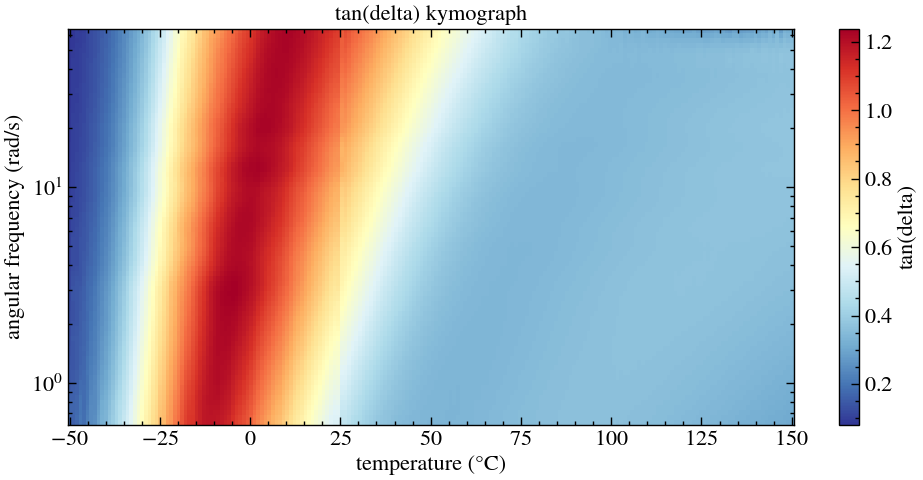

In [4]:
fig, ax = result.plot(
    colormap="RdYlBu_r",
    log_z=False,
    add_scatter=False,
    figsize=(10, 5),
)
plt.show()

## 5 — Slice: quantity vs frequency at fixed temperatures

Equivalent to the "Frequency sweeps" panel in RheoDash TORCh Analysis.

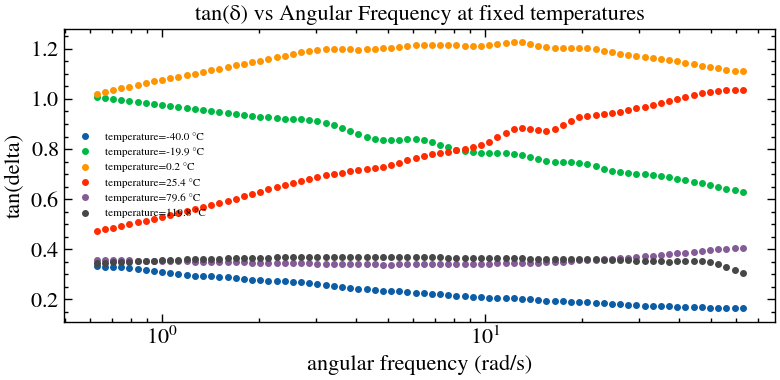

In [5]:
fig, ax = result.plot_slice_at_x(
    x_values=[-40, -20, 0, 25, 80, 120],
    log_x=True,
    log_y_axis=False,
    figsize=(8, 4),
)
ax.set_title("tan(δ) vs Angular Frequency at fixed temperatures")
plt.show()

## 6 — Slice: quantity vs temperature at fixed frequencies

Equivalent to the "Temperature ramps" panel in RheoDash TORCh Analysis.

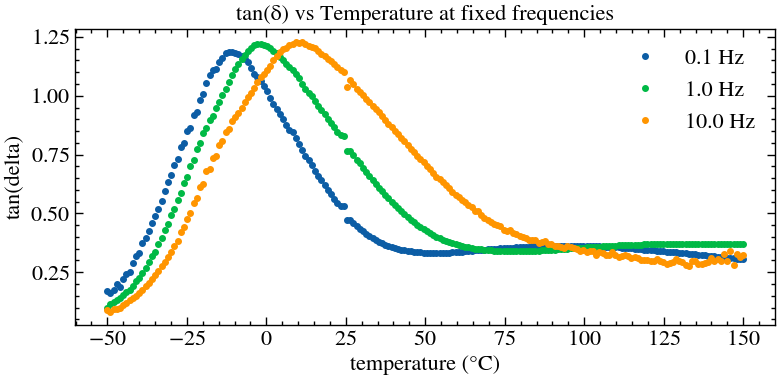

In [6]:
import math

# Frequencies in Hz → convert to rad/s
hz_values = [0.1, 1.0, 10.0]
rads_values = [2 * math.pi * f for f in hz_values]

fig, ax = result.plot_slice_at_y(
    y_values=rads_values,
    log_y_axis=False,
    figsize=(8, 4),
)
# Re-label legend with Hz
for line, hz in zip(ax.lines, hz_values):
    line.set_label(f"{hz} Hz")
ax.legend()
ax.set_title("tan(δ) vs Temperature at fixed frequencies")
plt.show()

## 7 — Other quantities

You can build a separate kymograph for any available viscoelastic quantity.

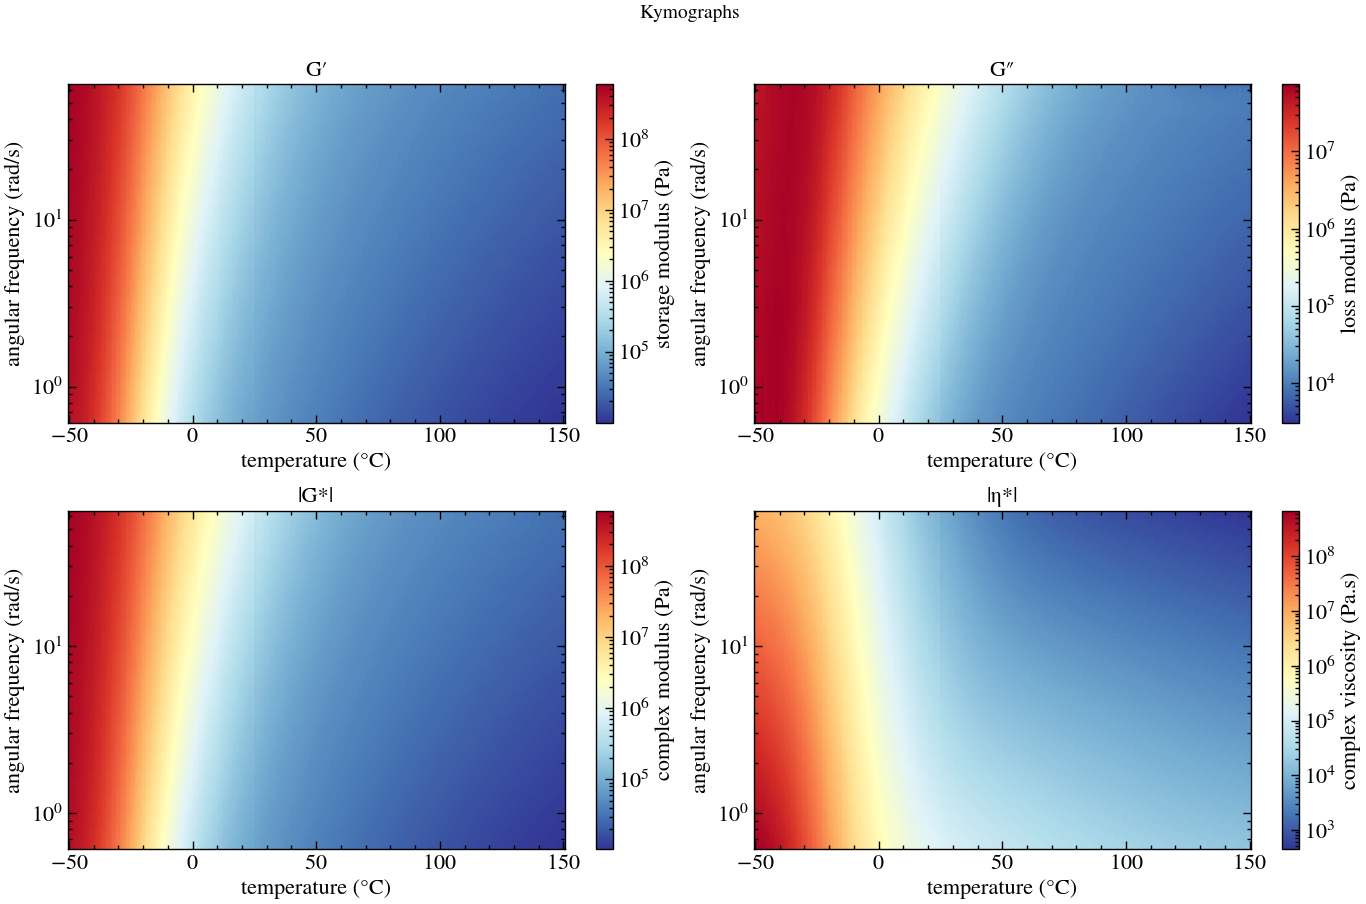

In [7]:
quantities_to_plot = [
    ("storage modulus",   "G′",   True),
    ("loss modulus",      "G″",   True),
    ("complex modulus",   "|G*|", True),
    ("complex viscosity", "|η*|", True),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (qty, label, log_z) in zip(axes.flat, quantities_to_plot):
    pipeline_qty = OWChirpAnalysis() + Kymograph(
        quantity=qty,
        n_x=200, n_y=80,
        interpolation="cubic",
        log_y=True,
    )
    res = pipeline_qty(experiment)

    res.plot(ax=ax, colormap="RdYlBu_r", log_z=log_z, title=label)

plt.suptitle("Kymographs", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 8 — Access the raw data and grid directly

The `KymographResult` exposes both the raw scatter points and the interpolated
`TwoDimensionalDataset` from `piblin`.

In [8]:
# Raw scatter arrays
print(f"Raw points: {len(result.raw_x)}")
print(f"Temperature range: {result.raw_x.min():.1f} to {result.raw_x.max():.1f} {result.x_unit}")
print(f"Frequency range:   {result.raw_y.min():.3g} to {result.raw_y.max():.3g} {result.y_unit}")

# Interpolated piblin TwoDimensionalDataset
grid_ds = result.grid
print(f"\nGrid dataset: {grid_ds.z_values.shape}  ({grid_ds.x_name} × {grid_ds.y_name})")
print(f"x range: {grid_ds.x_values.min():.1f} – {grid_ds.x_values.max():.1f} {grid_ds.x_unit}")
print(f"y range: {grid_ds.y_values.min():.3g} – {grid_ds.y_values.max():.3g} {grid_ds.y_unit}")

Raw points: 4179
Temperature range: -50.0 to 150.0 °C
Frequency range:   0.628 to 62.8 rad/s

Grid dataset: (200, 80)  (temperature × angular frequency)
x range: -50.0 – 150.0 °C
y range: 0.628 – 62.8 rad/s


## 9 — Export to Excel

In [9]:
output_path = "/tmp/kymograph_tan_delta.xlsx"
result.to_excel(output_path)
print(f"Saved to {output_path}")

Saved to /tmp/kymograph_tan_delta.xlsx


## 10 — Mutation Number kymograph

`MutationNumber` (Tutorial 6) outputs one measurement per angular
frequency, each containing a `time` × `mutation number` dataset with the
frequency stored in `measurement.conditions['Angular Frequency']`.
This is a natural fit for a 2-D map with **time** on the x-axis,
**angular frequency** on the y-axis and the **mutation number** as the
colour channel — i.e. another kymograph, but of $Mu(\omega, t)$
instead of a viscoelastic modulus.

`Kymograph` resolves each axis against dataset columns first, then
against `measurement.conditions`, so the same transform handles this
case without extra reshaping.  We reuse the OWChirp fixture from
Tutorial 6.

:::{seealso}
- Tutorial 6 — the underlying `MutationNumber` calculation.

KymographResult
---------------

Dependent Variable Data Properties: ndim=2, size=12000 (12000 bytes), shape=(200, 60)
Dependent Variable Labels: mutation number( )

Independent Variable Data Properties: n=2, lengths=[200, 60]
Independent Variable Labels: time(s), angular frequency()

Values of angular frequency () as a function of time (s)

time              = [ +31.7737  +35.3999 ... +749.7598 +753.3860]
angular frequency = [ +0.7670  +0.8258 ... +55.5668 +59.8253]

mutation number =

[[-0.0225 -0.0191 ... +0.0070 +0.0150]
 [-0.0178 -0.0175 ... +0.0053 +0.0109]
 ...
 [+0.0257 +0.0259 ... +0.0292 +0.0317]
 [+0.0183 +0.0191 ... +0.0291 +0.0319]]


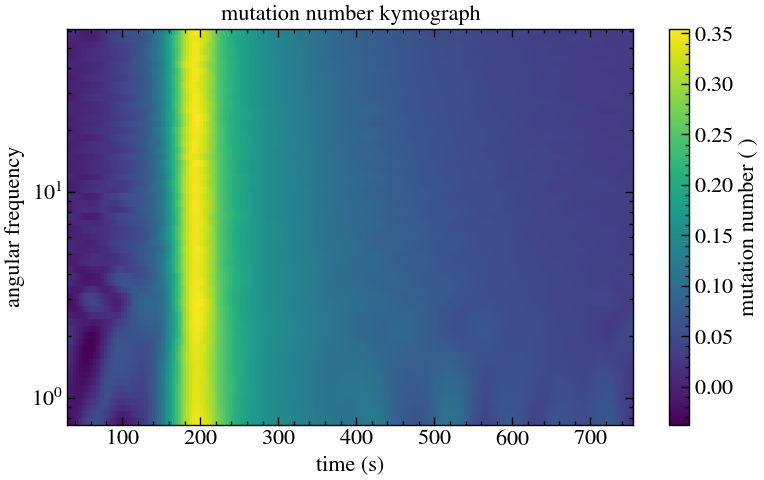

In [10]:
from hermes_rheo.transforms.mutation_number import MutationNumber

MU_FILEPATH = os.path.join(
    current_dir, "tutorial_data", "tutorial_5", "owchirp_tcs.txt",
)

mu_experiment = read_file(
    MU_FILEPATH,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)

mu_pipeline = (
    OWChirpAnalysis()
    + MutationNumber(dependent_variable="complex modulus")
    + Kymograph(
        quantity="mutation number",
        x="time",                    # dataset column
        y="angular frequency",       # from measurement.conditions
        n_x=200,
        n_y=60,
        interpolation="cubic",
        log_y=True,
    )
)

mu_result = mu_pipeline(mu_experiment)
print(mu_result)

fig, ax = mu_result.plot(colormap="viridis", add_scatter=False)
plt.show()